## Linear Regression 2.2: Predicting goals scored by a team in a FIFA WORLD CUP 2026 match

**Contributing Members:** *Nayandeep Shrestha (s397732)  |   Rajat Shrestha ()*

**Target:** `goals_scored`

**Eight explanatory variables:** team FIFA points, opponent FIFA points, team average goals scored (last 10), opponent average goals conceded (last 10), host nation, knockout stage, rest days, previous WC appearances

| *Part 1* | *Nayandeep Shrestha* | Validation, EDA, multicollinearity, train/test split |

| *Part 2* | *Rajat Shrestha* | OLS model, diagnostics, evaluation, improvement, Poisson Comparison|

## Imports

In [1]:
%matplotlib inline
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import OLSInfluence, variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson

from sklearn.model_selection import GroupKFold, GroupShuffleSplit, cross_validate
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


In [2]:
# Settings used throughout the notebook
SEED = 42
TARGET = "goals_scored"
NUMERIC_FEATURES = ["team_fifa_points", "opp_fifa_points", "team_gf_L10", "opp_ga_L10", "rest_days", "team_wc_appearances"]
BINARY_FEATURES = ["is_host", "is_knockout"]
FEATURES = NUMERIC_FEATURES[:4] + BINARY_FEATURES + NUMERIC_FEATURES[4:]

LABELS = {
    "team_fifa_points": "Team FIFA Points",
    "opp_fifa_points": "Opponent FIFA Points",
    "team_gf_L10": "Team avg goals scored(Last 10)",
    "opp_ga_L10": "Opponent avg goals conceded(Last 10)",
    "is_host": "Is Host",
    "is_knockout": "Is Knockout Match",
    "rest_days": "Rest Days",
    "team_wc_appearances": "Prev WC Appearances",
    "goals_scored": "Goals Scored",
}

FIG_DIR, TAB_DIR = Path("outputs/figures"), Path("outputs/tables")
for folder in (FIG_DIR, TAB_DIR):
    folder.mkdir(parents=True, exist_ok=True)

def section(title):
    """Prints a section title in the output."""
    print(f"\n{'=' * 80}\n{title}\n{'=' * 80}\n")

# PART 1

In [12]:
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 200, "axes.grid": True, "grid.alpha": 0.3})
rng = np.random.default_rng(SEED)

def save_fig(name: str) -> None:
    plt.tight_layout()
    plt.savefig(FIG_DIR / name, bbox_inches="tight")
    plt.show()
    print(f"Figure saved to {FIG_DIR / name}")

### 1. Load and Validate

In [13]:
df= pd.read_csv("wc2026_reg22_dataset.csv")

section("Data Validation")
print(f"Data shape: {df.shape}")
print(f"Data types:\n{df.dtypes.to_string()}")

checks = {
    "208 rows": len(df) == 208,
    "104 unique matches": df["match_id"].nunique() == 104,
    "every match has 2 rows": df["match_id"].value_counts().eq(2).all(),
    "48 unique teams": df["team"].nunique() == 48,
    "exactly 8 explanatory variables": len(FEATURES) == 8,
    "no missing values": df.isna().sum().sum() == 0,
    "no duplicate rows": not df.duplicated(["match_id", "team"]).any(),
    "binary features are 0 or 1": df[BINARY_FEATURES].isin([0, 1]).all().all(),
    "goals scored is non-negative": bool((df[TARGET] >= 0).all() and (df[TARGET] % 1 == 0).all()),
    "rest days is non-negative": bool((df["rest_days"] >= 0).all()),
}

for name, ok in checks.items():
    print(f"[{'OK' if ok else 'FAIL'}] {name}")

# each match has two mirrored rows
mirror = df.merge(df[["match_id", "team", TARGET]].rename(columns={"team": "opponent", TARGET: "opp_goals"}),
                  on=["match_id", "opponent"])
print(f" [OK] mirrored opponent rows fould for all rows: {len(mirror) == len(df)}")


Data Validation

Data shape: (208, 13)
Data types:
match_id                   str
team                       str
opponent                   str
stage                      str
team_fifa_points       float64
opp_fifa_points        float64
team_gf_L10            float64
opp_ga_L10             float64
is_host                  int64
is_knockout              int64
rest_days                int64
team_wc_appearances      int64
goals_scored             int64
[OK] 208 rows
[OK] 104 unique matches
[OK] every match has 2 rows
[OK] 48 unique teams
[OK] exactly 8 explanatory variables
[OK] no missing values
[OK] no duplicate rows
[OK] binary features are 0 or 1
[OK] goals scored is non-negative
[OK] rest days is non-negative
 [OK] mirrored opponent rows fould for all rows: True


### 2. Descriptive Statistics

In [14]:
section("Descriptive Statistics")

desc= df[FEATURES + [TARGET]].describe().T
desc["skewness"] = df[FEATURES + [TARGET]].skew()
desc = desc.round(3)
print(desc.to_string())
desc.to_csv(TAB_DIR / "descriptive_statistics.csv")



Descriptive Statistics

                     count      mean      std      min      25%       50%       75%      max  skewness
team_fifa_points     208.0  1617.207  162.682  1275.58  1505.35  1602.125  1745.072  1877.27    -0.126
opp_fifa_points      208.0  1617.207  162.682  1275.58  1505.35  1602.125  1745.072  1877.27    -0.126
team_gf_L10          208.0     1.959    0.672     0.70     1.30     1.900     2.500     3.70     0.312
opp_ga_L10           208.0     0.865    0.423     0.20     0.50     0.900     1.000     2.00     0.522
is_host              208.0     0.072    0.259     0.00     0.00     0.000     0.000     1.00     3.332
is_knockout          208.0     0.308    0.463     0.00     0.00     0.000     1.000     1.00     0.839
rest_days            208.0     5.221    0.845     3.00     5.00     5.000     6.000     8.00     0.337
team_wc_appearances  208.0     8.149    6.210     0.00     3.00     6.000    14.000    22.00     0.492
goals_scored         208.0     1.481    1.393   

### 3. Target Variable (goals scored by a team in a match)


Mean = 1.481, variance = 1.942, variance/mean = 1.31
(For a Poisson count variable variance ~ mean. A ratio far above 1 means overdispersion.)
Share of rows with 0 goals: 26.4%; max goals: 7

Frequency of goals scored:
 goals_scored
0    55
1    71
2    39
3    25
4    10
5     5
6     2
7     1


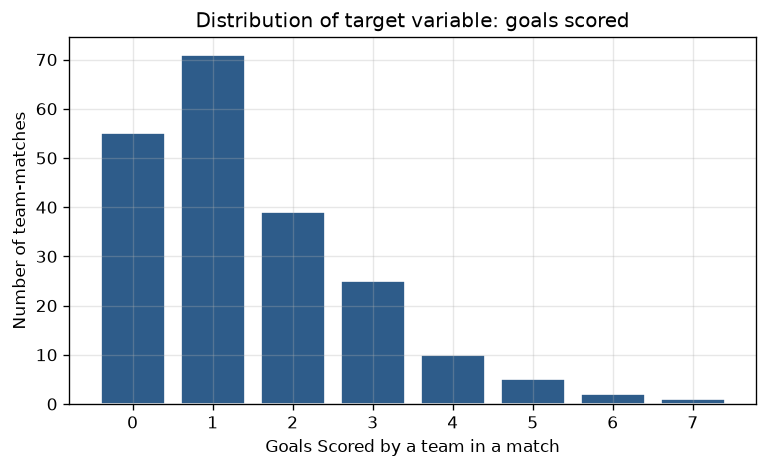

Figure saved to outputs/figures/target_distribution.png
              observed  expected
goals_scored                    
0                   55      47.3
1                   71      70.1
2                   39      51.9
3                   25      25.6
4                   10       9.5
5                    5       2.8
6                    2       0.7
7                    1       0.1


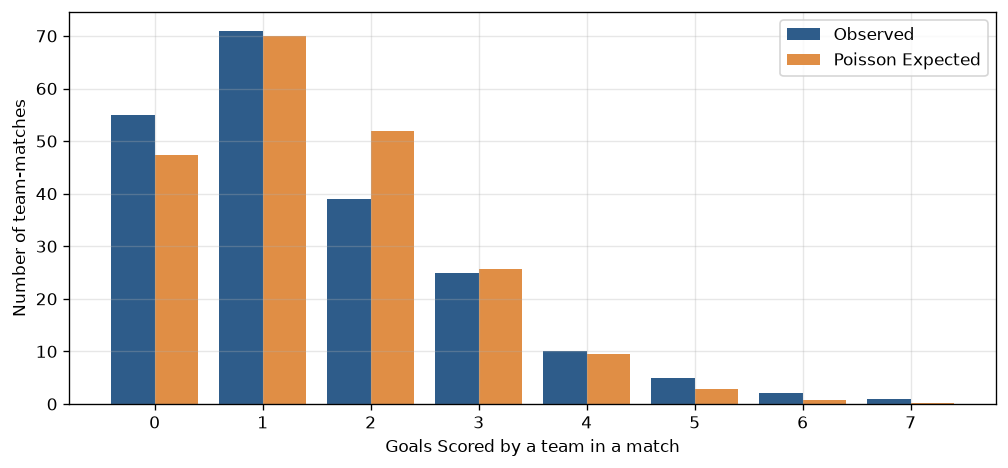

Figure saved to outputs/figures/target_observed_vs_expected.png


In [15]:
y = df[TARGET]
print(f"Mean = {y.mean():.3f}, variance = {y.var():.3f}, variance/mean = {y.var() / y.mean():.2f}")
print("(For a Poisson count variable variance ~ mean. A ratio far above 1 means overdispersion.)")
print(f"Share of rows with 0 goals: {(y == 0).mean():.1%}; max goals: {y.max()}")
counts = y.value_counts().sort_index()
print("\nFrequency of goals scored:\n", counts.to_string())
counts.rename("rows").to_csv(TAB_DIR / "goals_frequency.csv")

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.bar(counts.index, counts.values, color="#2e5c8a", edgecolor="white")
ax.set_xlabel("Goals Scored by a team in a match")
ax.set_ylabel("Number of team-matches")
ax.set_title("Distribution of target variable: goals scored")
ax.set_xticks(counts.index)
save_fig("target_distribution.png")

# Observed vs Poisson expected goal counts
k = np.arange(y.max() + 1)
observed = y.value_counts().reindex(k, fill_value=0)
expected = stats.poisson.pmf(k, y.mean()) * len(y)
print(pd.DataFrame({"observed": observed, "expected": expected.round(1)}))

fig, ax = plt.subplots(figsize=(8.5, 4))
ax.bar(k - 0.2, observed, 0.4, label="Observed", color="#2e5c8a")
ax.bar(k + 0.2, expected, 0.4, label="Poisson Expected", color="#e08e45")
ax.set_xlabel("Goals Scored by a team in a match")
ax.set_ylabel("Number of team-matches")
ax.set_xticks(k)
ax.legend()
save_fig("target_observed_vs_expected.png")

### 4. Distirbution of Predictors + Outliers

Histograms of the numeric predictors, bar charts of the binary ones, and an IQR-based outlier check

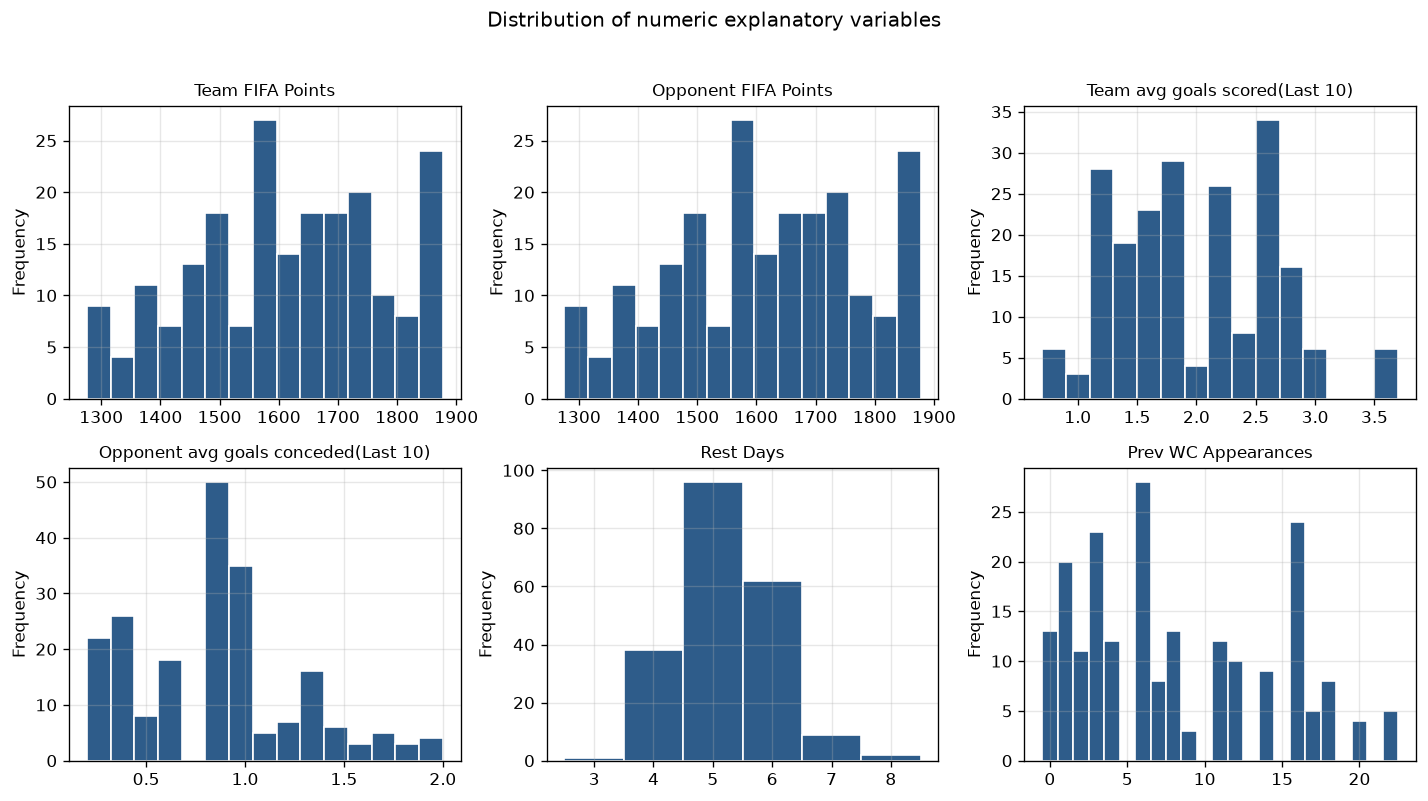

Figure saved to outputs/figures/numeric_features_distribution.png


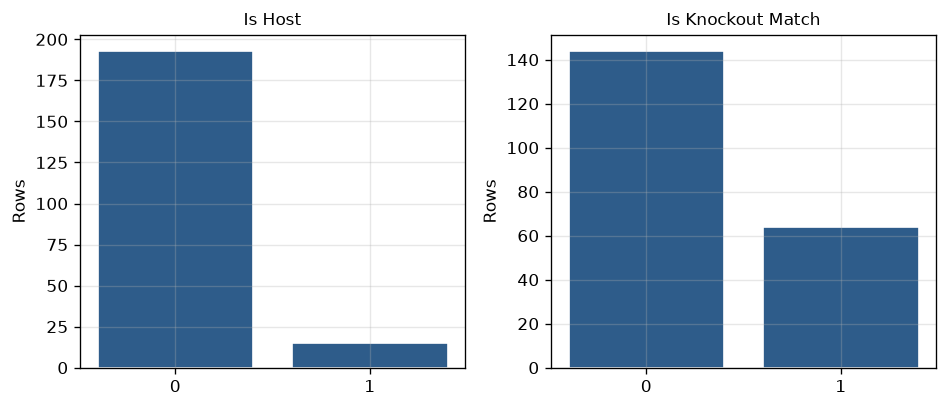

Figure saved to outputs/figures/binary_features_distribution.png
           variable  lower_fence  upper_fence  rows_flagged                                                   flagged_values
   team_fifa_points      1145.77      2104.66             0                                                                 
    opp_fifa_points      1145.77      2104.66             0                                                                 
        team_gf_L10        -0.50         4.30             0                                                                 
         opp_ga_L10        -0.25         1.75             7                      New Zealand: 1.8 (3rows); Sweden: 2 (4rows)
          rest_days         3.50         7.50             3 Australia: 8 (1rows); England: 3 (1rows); Switzerland: 8 (1rows)
team_wc_appearances       -13.50        30.50             0                                                                 


In [16]:
# Histograms of numeric explanatory variables
fig, axes = plt.subplots(2, 3, figsize=(12, 6.5))
for ax, col in zip(axes.ravel(), NUMERIC_FEATURES):
    if (df[col] % 1  == 0).all():
        bins = np.arange(df[col].min() - 0.5, df[col].max() + 1.5)
    else:
        bins = 15
    ax.hist(df[col], bins=bins, color="#2e5c8a", edgecolor="white")
    if df[col].nunique() <= 10:
        ax.set_xticks(sorted(df[col].unique()))
    ax.set_title(LABELS[col], fontsize=10)
    ax.set_ylabel("Frequency")
fig.suptitle("Distribution of numeric explanatory variables", y=1.02)
save_fig("numeric_features_distribution.png")

# Bar plots of binary explanatory variables
fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))
for ax, col in zip(axes, BINARY_FEATURES):
    vc = df[col].value_counts().sort_index()
    ax.bar(vc.index.astype(str), vc.values, color="#2e5c8a", edgecolor="white")
    ax.set_title(LABELS[col], fontsize=10)
    ax.set_ylabel("Rows")
save_fig("binary_features_distribution.png")

# Outlier Check using IQR method
rows = []
for col in NUMERIC_FEATURES:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outliers = df[(df[col] < lower) | (df[col] > upper)]
    owner = "opponent" if col.startswith("opp_") else "team"
    flagged = outliers.groupby(owner)[col].agg(["first", "size"])
    rows.append({
        "variable": col,
        "lower_fence": round(lower, 2),
        "upper_fence": round(upper, 2),
        "rows_flagged": len(outliers),
        "flagged_values": "; ".join(f"{t}: {r['first']:g} ({int(r['size'])}rows)" for t, r in flagged.iterrows())})

outliers = pd.DataFrame(rows)
print(outliers.to_string(index=False))
outliers.to_csv(TAB_DIR / "outlier_check.csv", index=False)

### 5. Relationships

Correlation matrix, correlation of each predictor with goals, scatter plots with trend lines, and goal averages by group.

Correlation of each predictor with the target variable (goals scored):
 team_fifa_points       0.385
opp_fifa_points       -0.339
team_wc_appearances    0.336
team_gf_L10            0.303
opp_ga_L10             0.254
is_host                0.104
rest_days             -0.099
is_knockout           -0.013

Strongest correlation between predictors:
            var_1               var_2   corr
team_fifa_points team_wc_appearances  0.780
team_fifa_points         team_gf_L10  0.631
 opp_fifa_points          opp_ga_L10 -0.554
     team_gf_L10 team_wc_appearances  0.509
team_fifa_points         is_knockout  0.337


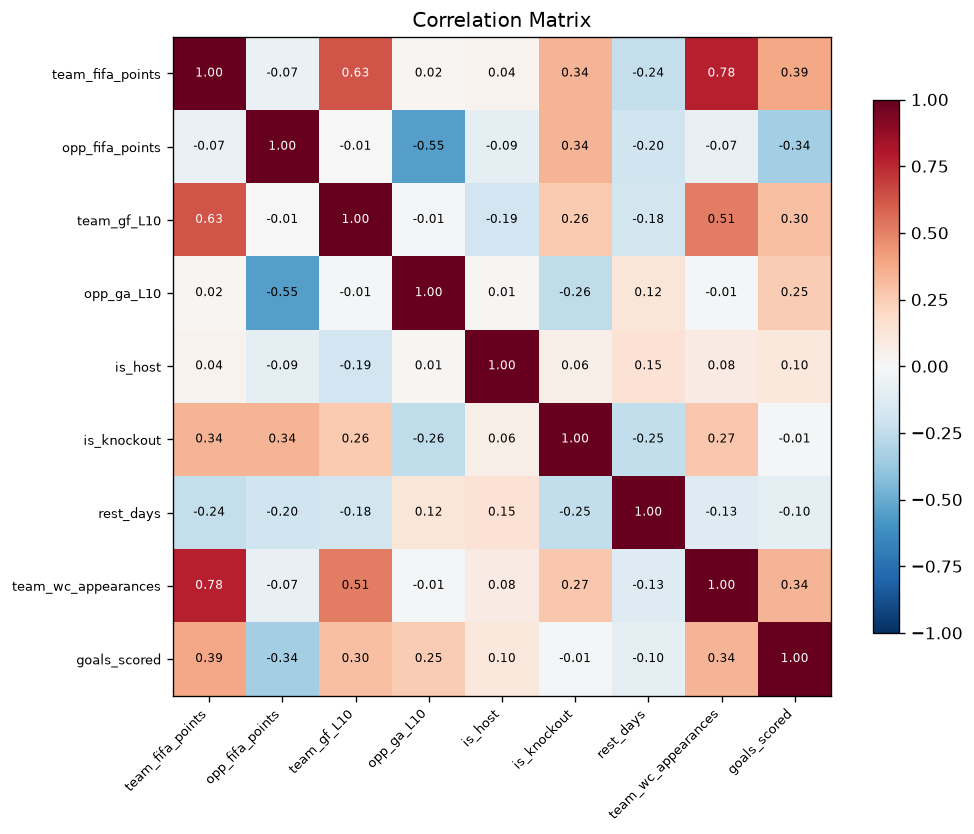

Figure saved to outputs/figures/correlation_heatmap.png


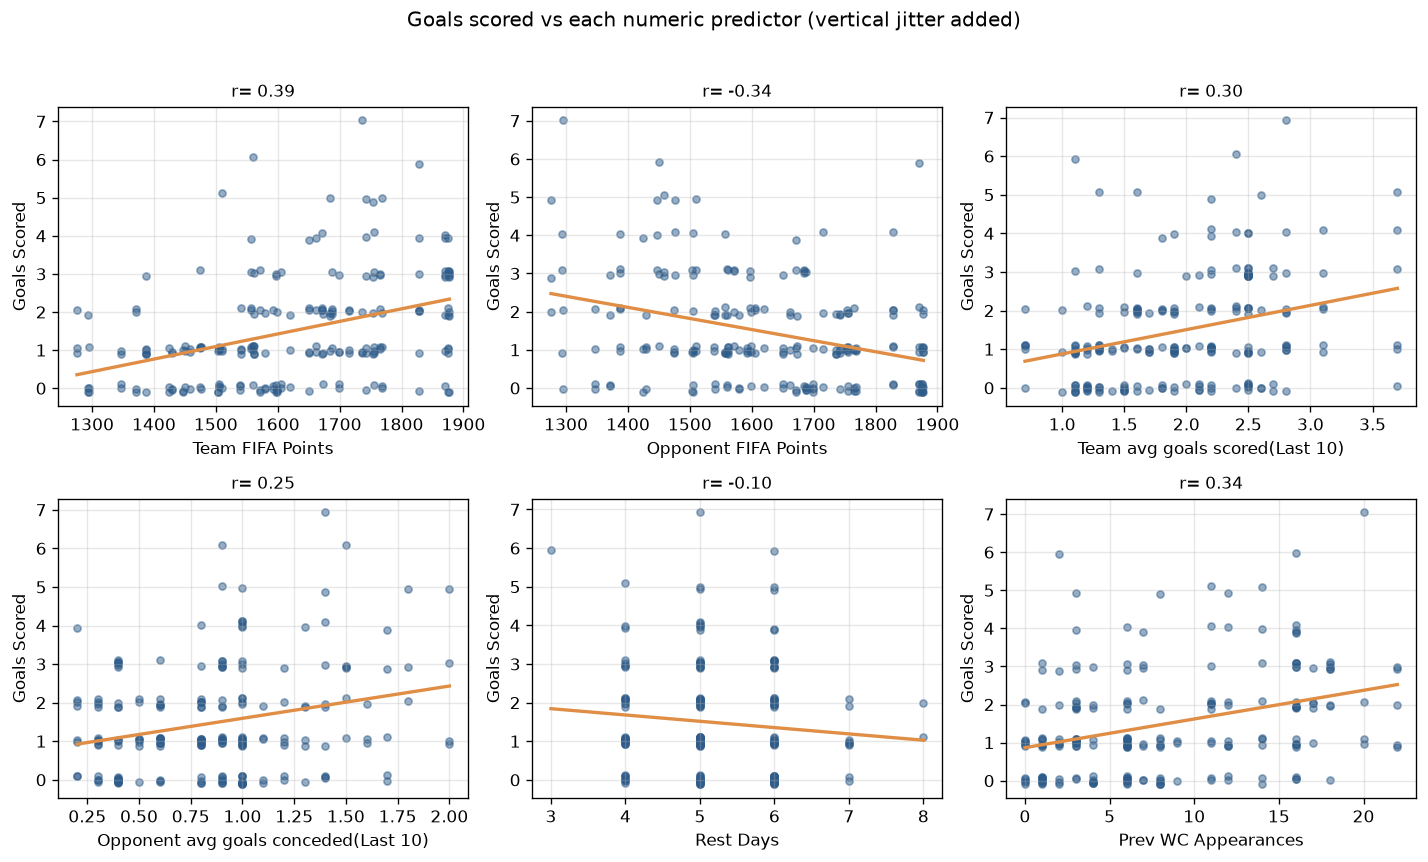

Figure saved to outputs/figures/target_vs_scatter_numeric.png


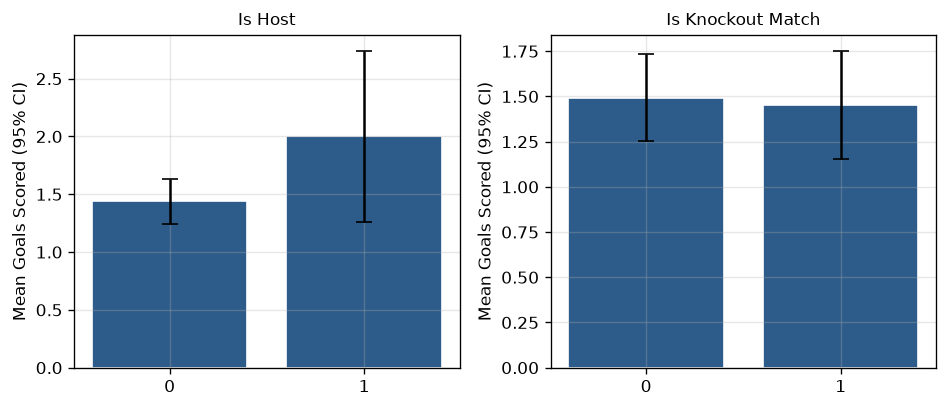

Figure saved to outputs/figures/target_vs_binary.png

Mean goals scored by tournament stage:
                count   mean
stage                      
Bronze final       2  5.000
Final              2  0.500
Group Stage      144  1.493
Quarter-final      8  1.500
Round of 16       16  1.438
Round of 32       32  1.312
Semi-final         4  1.250


In [17]:
cols = FEATURES + [TARGET]
corr = df[cols].corr().round(3)
corr.to_csv(TAB_DIR / "correlation_matrix.csv")

target_corr = corr[TARGET].drop(TARGET).sort_values(key=np.abs, ascending=False)
print("Correlation of each predictor with the target variable (goals scored):\n", target_corr.to_string())
target_corr.round(3).rename("corr_with_goals").to_csv(TAB_DIR / "corr_with_target.csv")

pairs = []
for i, a in enumerate(FEATURES):
    for b in FEATURES[i + 1:]:
        pairs.append((a, b, corr.at[a, b]))
pairs = pd.DataFrame(pairs, columns = ["var_1", "var_2", "corr"]).sort_values("corr", key=np.abs, ascending=False)
print("\nStrongest correlation between predictors:\n", pairs.head(5).round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)))
ax.set_yticks(range(len(cols)))
ax.set_xticklabels(cols, rotation=45, ha="right", fontsize=8)
ax.set_yticklabels(cols, fontsize=8)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(corr.values[i, j]) > 0.6 else "black")
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Correlation Matrix")
save_fig("correlation_heatmap.png")

# predictor vs target scatter plots
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, col in zip(axes.ravel(), NUMERIC_FEATURES):
    jitter = rng.uniform(-0.12, 0.12, len(df))
    ax.scatter(df[col], df[TARGET] + jitter, alpha=0.5, s=18, color="#2e5c8a")
    slope, intercept = np.polyfit(df[col], df[TARGET], 1)
    xs = np.linspace(df[col].min(), df[col].max(), 100)
    ax.plot(xs, slope * xs + intercept, color="#e08e45", lw=2)
    ax.set_xlabel(LABELS[col], fontsize=10)
    ax.set_ylabel(LABELS[TARGET])
    ax.set_title(f"r= {corr.loc[col, TARGET]:.2f}", fontsize=10)
fig.suptitle("Goals scored vs each numeric predictor (vertical jitter added)", y = 1.02)
save_fig("target_vs_scatter_numeric.png")

# binary predictors : mean goals per group
fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))
group_rows = []
for ax, col in zip(axes, BINARY_FEATURES):
    g = df.groupby(col)[TARGET].agg(["mean", "std", "count"])
    g["sem"] = g["std"] / np.sqrt(g["count"])
    ax.bar(g.index.astype(str), g["mean"], yerr=1.96 * g["sem"], capsize=5, color="#2e5c8a", edgecolor="white")
    ax.set_title(LABELS[col], fontsize=10)
    ax.set_ylabel("Mean Goals Scored (95% CI)")
    for level, r in g.iterrows():
        group_rows.append({"variable": col,
                            "level": level,
                            "mean_goals": round(r["mean"], 3), 
                            "sd": round(r["std"], 3),
                            "n": int(r["count"])
                })
save_fig("target_vs_binary.png")
group_table = pd.DataFrame(group_rows)
group_table.to_csv(TAB_DIR / "binary_group_means.csv", index=False)

stage_table = df.groupby("stage")[TARGET].agg(["count", "mean"]).round(3)
print("\nMean goals scored by tournament stage:\n", stage_table.to_string())
stage_table.to_csv(TAB_DIR / "goals_by_stage.csv")

### 6. Multicollinearity (Vif)

Variance inflation factors (Vif) show whether predictors overlap too much.
Rule of thumb: VIF > 5 moderate, >10 serious.

In [18]:
X = sm.add_constant(df[FEATURES])
vif = pd.DataFrame({
    "variable": FEATURES,
    "VIF": [variance_inflation_factor(X.values, i + 1) for i in range(len(FEATURES))],
}).round(3)
vif["verdict"] = np.where(vif["VIF"] > 10, "serious (>10)", np.where(vif["VIF"] > 5, "moderate (5-10)", "Fine (<5)"))
print(vif.to_string(index=False))
print(f"Condition number of the design matrix: {np.linalg.cond(X.values):.1f}")
print("(This is large mainly because the variables are on very different scales," \
" e.g. FIFA points ~1500 vs binary 0/1. VIF is the more informative check here.)")
vif.to_csv(TAB_DIR / "vif.csv", index=False)

           variable   VIF   verdict
   team_fifa_points 3.411 Fine (<5)
    opp_fifa_points 1.631 Fine (<5)
        team_gf_L10 1.820 Fine (<5)
         opp_ga_L10 1.465 Fine (<5)
            is_host 1.141 Fine (<5)
        is_knockout 1.371 Fine (<5)
          rest_days 1.164 Fine (<5)
team_wc_appearances 2.614 Fine (<5)
Condition number of the design matrix: 55089.3
(This is large mainly because the variables are on very different scales, e.g. FIFA points ~1500 vs binary 0/1. VIF is the more informative check here.)


### 7. Train / Test Split (by match)

Splitting the data 80/20 by match so both rows of a match stay on the same side.

In [19]:
splitter = GroupShuffleSplit(n_splits=1, test_size= 0.20, random_state = SEED)
train_idx, text_idx = next(splitter.split(df, groups=df["match_id"]))
train, test = df.iloc[train_idx].copy(), df.iloc[text_idx].copy()
print(f"Train: {len(train)} rows / {train['match_id'].nunique()} matches")
print(f"Test: {len(test)} rows / {test['match_id'].nunique()} matches")
print(f"Overlap of matches between train and test: {len(set(train['match_id']) & set(test['match_id']))} (must be 0)")
print(f"Mean goals - train: {train[TARGET].mean():.3f}, test: {test[TARGET].mean():.3f}")
print(f"Knockout share - train: {train['is_knockout'].mean():.1%}, test: {test['is_knockout'].mean():.1%}")


Train: 166 rows / 83 matches
Test: 42 rows / 21 matches
Overlap of matches between train and test: 0 (must be 0)
Mean goals - train: 1.590, test: 1.048
Knockout share - train: 30.1%, test: 33.3%


### Part 2 -- Modelling,diagnostics and evaluation


In [20]:
plt.rcParams.update({"figure.dpi":120, "savefig.dpi":200, 'axes.grid':True, 'grid.alpha':0.3})
rng=np.random.default_rng(SEED)
ALPHA_ELM = 0.10 #backward-elimination threshold (p-value): change to 0.05 for a stricter model
CV_FOLDS = 5

def save_fig(name:str) -> None:
    plt.tight_layout()
    plt.savefig(FIG_DIR/name, bbox_inches="tight")
    plt.show()
    print(f"saved figure:{name}")

def regression_metrics(y_true, y_pred, n_predictors: int) -> dict:
    """R2, adjusted R2, RMSE, MAE."""
    n=len(y_true)
    r2=r2_score(y_true, y_pred)
    adj=1-(1-r2)*(n-1)/(n-n_predictors-1)
    return {"R2": r2, "Adj_R2": adj,
            "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
            "MAE":mean_absolute_error(y_true, y_pred)}




### 0. Load Data
Part2 reuses 'df', 'train' and 'test' created in Part 1.

**Findings:** *Part 2 uses the same 80/20 match-level split from Part 1 (166 training rows, 42 test rows). Models are fitted on the training data only, and the test set is held back for final evaluation. Because the test set is small, its results should be read with caution.*

In [24]:
y_all = df[TARGET]
section("0.DATA")
print(f"ALL rows: {len(df)}| train:{len(train)} ({train['match_id'].nunique()} matches) |"
      f"test: {len(test)} ({test['match_id'].nunique()} matches)")

assert set(train['match_id']).isdisjoint(test['match_id']), "train/test share matches"
assert len(train) + len(test) == len(df), 'rows lost in split'
assert train.groupby('match_id').size().eq(2).all(),"a train match is missing a row"
assert test.groupby('match_id').size().eq(2).all(),"a test match is missinga row"
print("split checks passed")


0.DATA

ALL rows: 208| train:166 (83 matches) |test: 42 (21 matches)
split checks passed


### A. OLS MODEL FOR INFERENCE (all 208 rows)

Fits the multiple linear regression on all rows: coefficients, p-calue, confidence intervals, standarised effects, and match-clusteres robust standard errors

**Findings:***The overall OLS model accounts for 28.5% of the variation in goals (R² = 0.285, adjusted R² = 0.257) and the F-test is highly significant (p = 1.3e-11), meaning that the predictors are collectively significant. The rest of the difference is to be expected as football goals are highly random.

The biggest effect p = 0.001 is opponent points (and 0.003 if match-clustered standard errors are used): for every additional 100 points in opponent's score, the expected number of goals drops by approximately 0.21. The team average goals scored fall close to classical standard errors (p = 0.053) but are significant with clustering of matches (p = 0.045). There is a positive (marginal) change in Team FIFA points and host nation, under either measure. The other predictors do not appear to have any significant effect.

When the clustering by match affects some of the p-values in both directions, the main conclusions remain valid, but need to be approached with caution; some of the p-values should be kept as borderline values.*



A. MULTIPLE LINEAR REGRESSION (OLS) -- all 208 rows

                            OLS Regression Results                            
Dep. Variable:           goals_scored   R-squared:                       0.285
Model:                            OLS   Adj. R-squared:                  0.257
Method:                 Least Squares   F-statistic:                     9.934
Date:                Sun, 11 Oct 2026   Prob (F-statistic):           1.32e-11
Time:                        14:28:04   Log-Likelihood:                -328.70
No. Observations:                 208   AIC:                             675.4
Df Residuals:                     199   BIC:                             705.4
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------

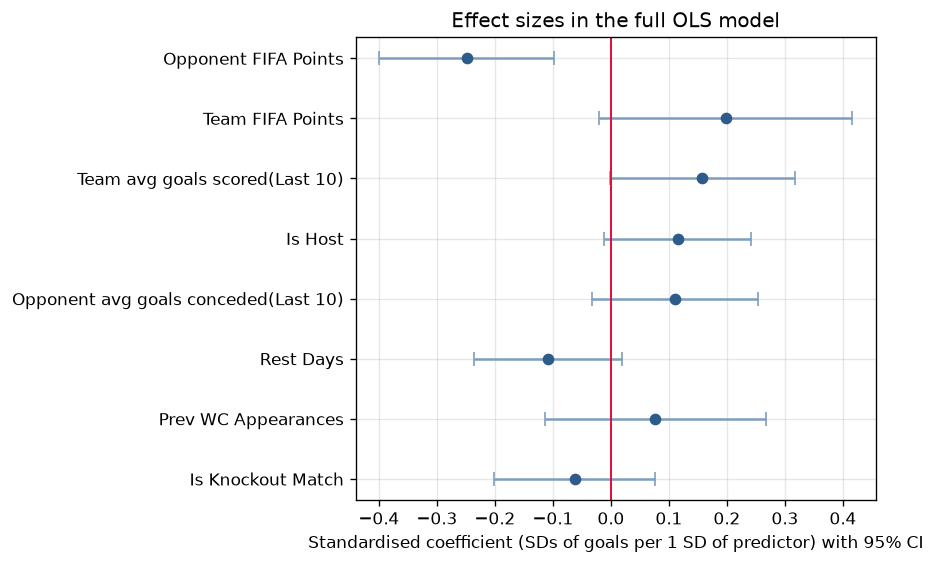

saved figure:p2_standardised_coefficients.png


In [30]:
section("A. MULTIPLE LINEAR REGRESSION (OLS) -- all 208 rows")
X_all = sm.add_constant(df[FEATURES])
ols=sm.OLS(y_all, X_all).fit()
print(ols.summary())
(TAB_DIR / "p2_ols_full_summary.txt").write_text(str(ols.summary()))

ci=ols.conf_int()
coef_table=pd.DataFrame({
    "coef":ols.params, "std_err":ols.bse, "t":ols.tvalues, "p_value":ols.pvalues,
    "ci_low":ci[0], "ci_high":ci[1]
})
#standardised coefficient = coef*sd(x)/sd(y): effect as a 1-SD change in x, in SDs of y (comparable across variables)
coef_table['std_beta']=[np.nan]+[ols.params[f]*df[f].std()/y_all.std() for f in FEATURES]
coef_table=coef_table.round(4)
print("\nCoefficeint Table:\n", coef_table.to_string())
coef_table.to_csv(TAB_DIR/ "pe_ols_coefficients.csv")

print(f"\nR2 = {ols.rsquared:.3f} | adjusted R2= {ols.rsquared_adj:.3f}|"
      f"F={ols.fvalue:.2f}(p={ols.f_pvalue:.2g})| AIC={ols.aic:.1f}| BIC={ols.bic:.1f}")
print(f"Residual standard error (RMSE on all data)={np.sqrt(ols.mse_resid):.3f} goals")

#robust stabdarad errors, clustered by match: the two rowss of a match are not independent
match_codes= pd.factorize(df['match_id'])[0]
ols_cl=sm.OLS(y_all,X_all).fit(cov_type='cluster', cov_kwds={"groups":match_codes})
robust=pd.DataFrame({
    "coef":ols.params, 'se_classical':ols.bse, 'se_cluster_by_match':ols_cl.bse,
    "p_classical":ols.pvalues,"p_cluster_by_match":ols_cl.pvalues,
}).round(4)
print("\nClassical vs match-clustered standard erros:\n", robust.to_string())
robust.to_csv(TAB_DIR/ "p2_robust_standard_errors.csv")

#coefficient plot (standardised, with 95% CI)
sd_ratio=pd.Series({f:df[f].std()/y_all.std() for f in FEATURES})
std_ci_low=ci.loc[FEATURES, 0]*sd_ratio
std_ci_high=ci.loc[FEATURES, 1]*sd_ratio
std_beta=coef_table.loc[FEATURES,'std_beta']
order=std_beta.abs().sort_values().index
fig,ax=plt.subplots(figsize=(7.5, 4.8))
ypos=np.arange(len(order))
ax.errorbar(std_beta[order],ypos,
            xerr=[std_beta[order]-std_ci_low[order], std_ci_high[order]-std_beta[order]],
            fmt='o',color="#2E5C8A", ecolor="#7F9DBF", capsize=4)
ax.axvline(0,color='crimson', lw=1.2)
ax.set_yticks(ypos)
ax.set_yticklabels([LABELS[f] for f in order])
ax.set_xlabel("Standardised coefficient (SDs of goals per 1 SD of predictor) with 95% CI")
ax.set_title("Effect sizes in the full OLS model")
save_fig("p2_standardised_coefficients.png")

## B. REGRESSION ASSUMPTION CHECKS (on the full-data OLS residuals)

Checks linearity, constant variance, normality of residuals, independence ( rows of the same match) and influential observations.

Findings:




B. DIAGNOSTICS



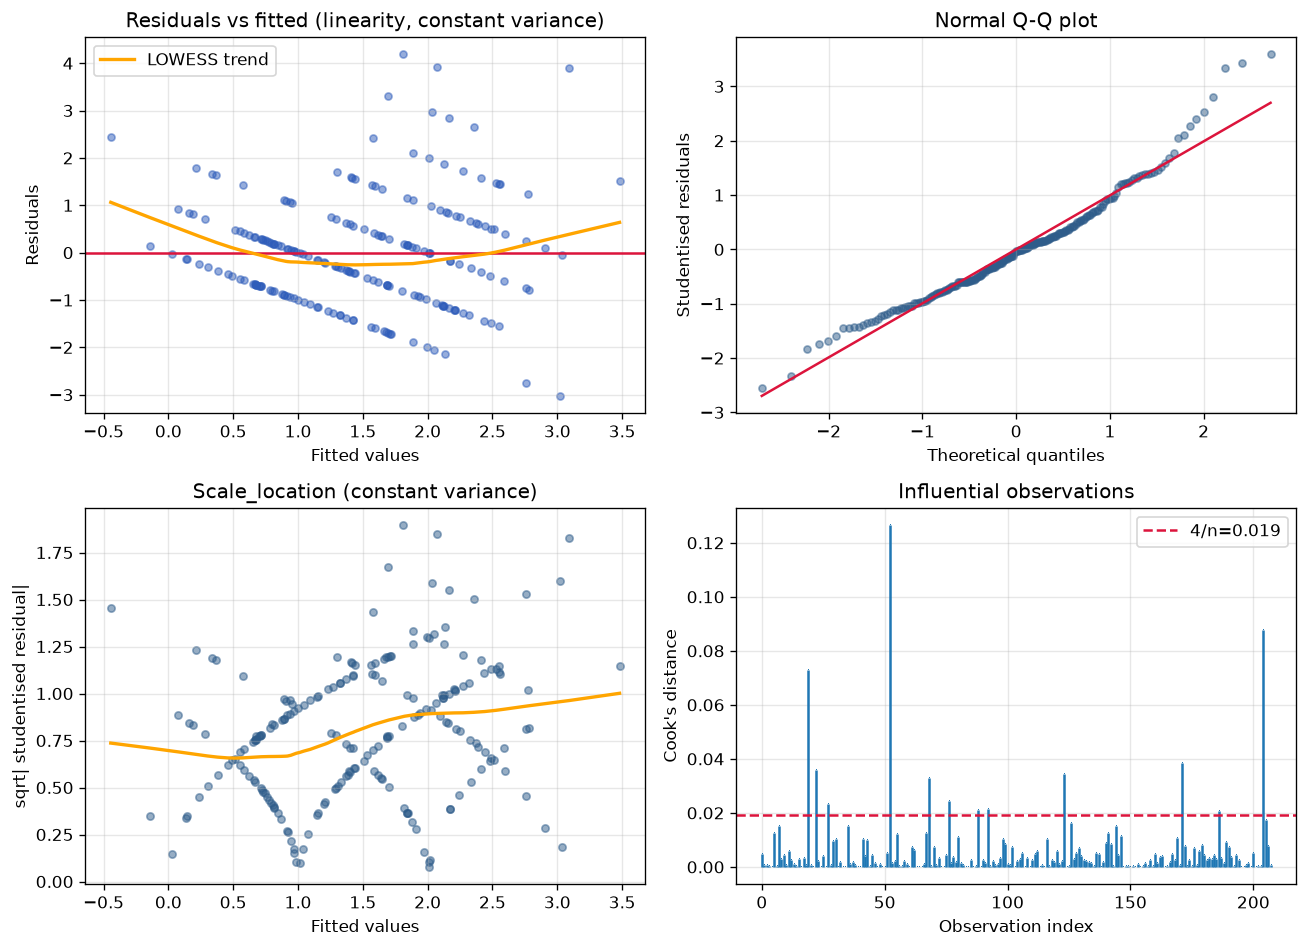

saved figure:p2_diagnostic_plots.png


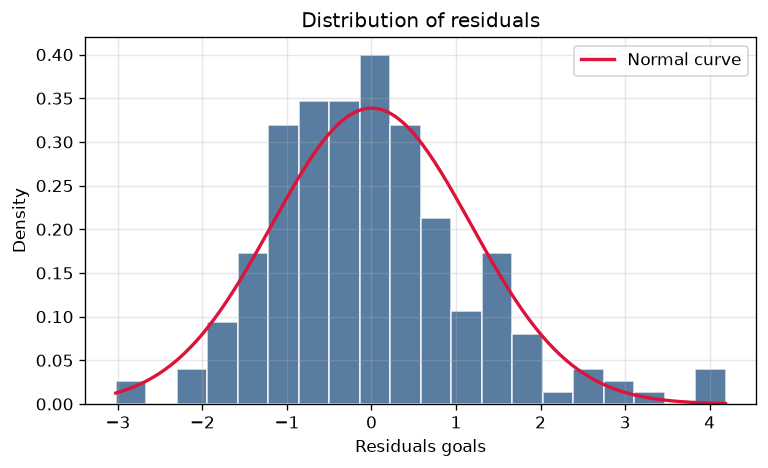

saved figure:p2_resiudal_histogram.png


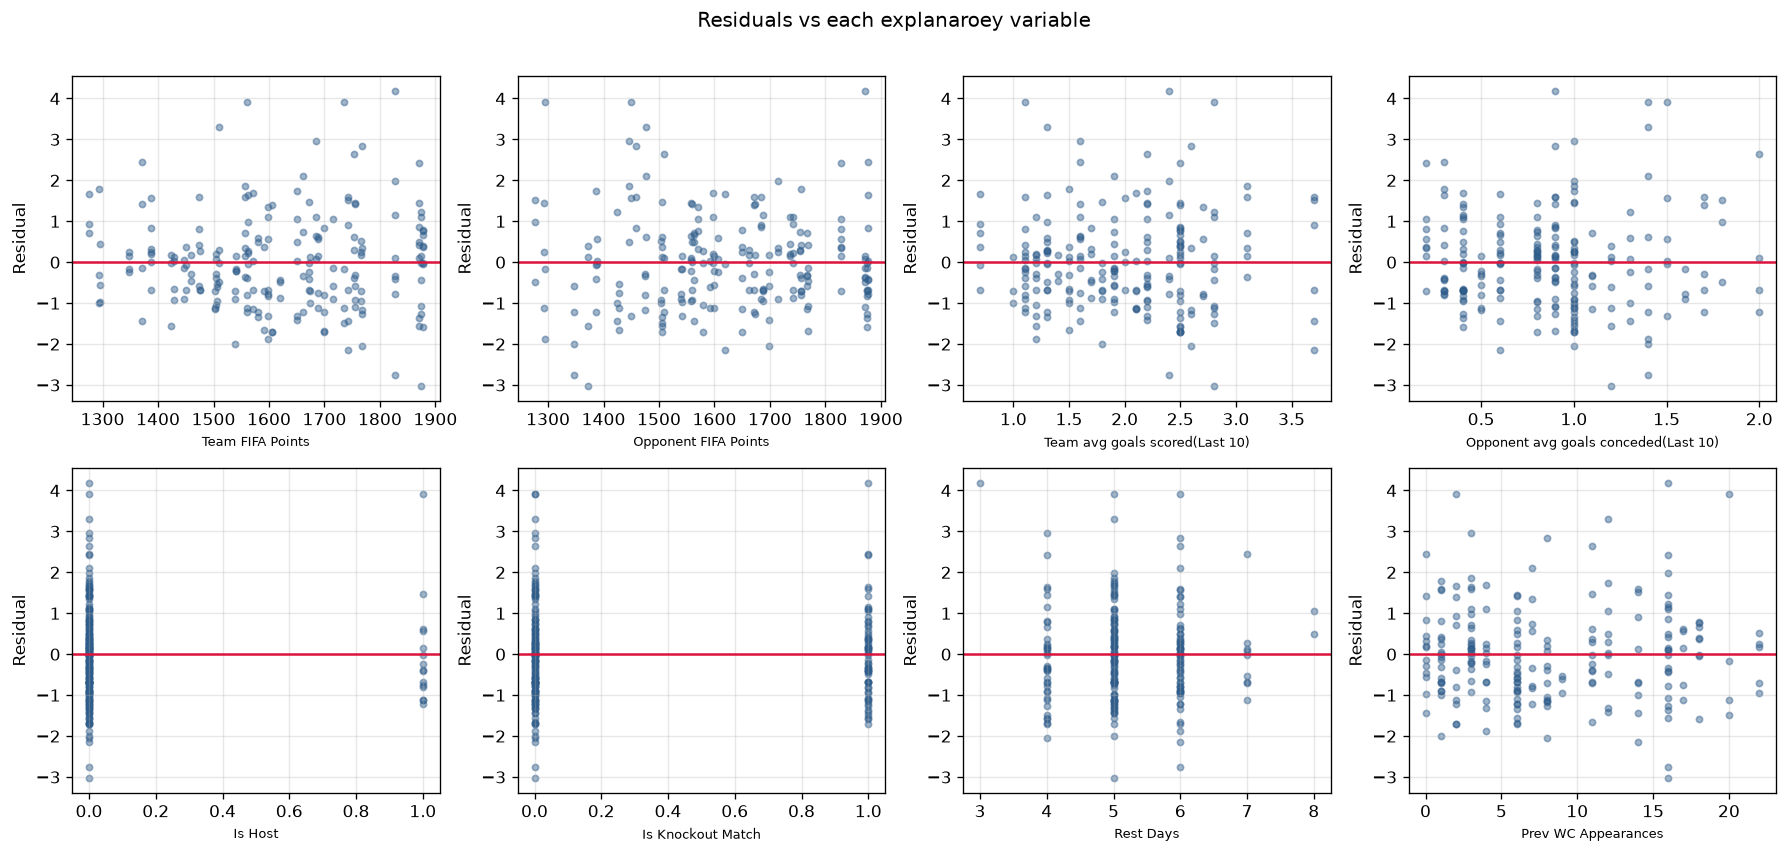

saved figure:p2_residuals_vs_predictors.png
                                           test   statistic  p_value                                                      reading
            Shapiro_Wilk normality of residuals     W=0.967   0.0001                               p<0.05 -> residuals not normal
            Residual skewness / excess kurtosis 0.74 / 1.21      NaN                              0 / 0 for a normal distribution
               Breusch-Pagan heteroscedasticity  LM = 18.18   0.0199                            p < 0.05 -> non-constant variance
                      Durbin-Watson (row order)        1.97      NaN ~2 means no serial correlation (row order is arbitrary here)
Correlation of the two residuals within a match       0.180      NaN                           far from 0 -> rows not independent
               Observations with Cook's D > 4/n          12      NaN                                           threshold = 0.0192
          Observations with leverage > 2(k+1)/

In [47]:
section("B. DIAGNOSTICS")
fitted, resid = ols.fittedvalues, ols.resid
infl=OLSInfluence(ols)
student_resid=infl.resid_studentized_internal
cooks=infl.cooks_distance[0]
leverage= infl.hat_matrix_diag
n, k =len(df), len(FEATURES)

# --- B1 plots:residuals vs fitted, QQ scale-location, Cook's Distance
fig,axes=plt.subplots(2,2,figsize=(11,8))
ax=axes[0,0]
ax.scatter(fitted, resid, alpha=0.5, s=18, color="#2E5CBA")
ax.axhline(0, color='crimson')
lo=sm.nonparametric.lowess(resid, fitted, frac=0.6)
ax.plot(lo[:, 0], lo[:, 1], color="orange", lw=2, label="LOWESS trend")
ax.set_xlabel("Fitted values")
ax.set_ylabel("Residuals")
ax.set_title("Residuals vs fitted (linearity, constant variance)")
ax.legend()
ax=axes[0,1]
(osm,osr),(slope,intercept,r)=stats.probplot(student_resid, dist="norm")
ax.scatter(osm,osr, alpha=0.5, s=18, color="#2E5C8A")
ax.plot(osm,intercept+slope*np.asarray(osm),color="crimson")
ax.set_xlabel("Theoretical quantiles")
ax.set_ylabel("Studentised residuals")
ax.set_title("Normal Q-Q plot")
ax=axes[1,0]
ax.scatter(fitted, np.sqrt(np.abs(student_resid)),alpha=0.5, s=19, color="#2E5C8A")
lo=sm.nonparametric.lowess(np.sqrt(np.abs(student_resid)),fitted,frac=0.6)
ax.plot(lo[:,0],lo[:,1],color="orange",lw=2)
ax.set_xlabel("Fitted values")
ax.set_ylabel("sqrt| studentised residual|")
ax.set_title("Scale_location (constant variance)")
ax=axes[1,1]
ax.stem(np.arange(n), cooks, markerfmt=",", basefmt=" ")
ax.axhline(4/n, color="crimson", ls="--", label=f"4/n={4/n:.3f}")
ax.set_xlabel("Observation index")
ax.set_ylabel("Cook's distance")
ax.set_title("Influential observations")
ax.legend()
save_fig("p2_diagnostic_plots.png")

# ---B2 residual histogram
fig, ax = plt.subplots(figsize=(6.5,4))
ax.hist(resid, bins=20, density=True, color="#2E5C8A", edgecolor="white", alpha=0.8)
xs=np.linspace(resid.min(), resid.max(), 200)
ax.plot(xs, stats.norm.pdf(xs,resid.mean(), resid.std()), color="crimson", lw=2, label="Normal curve")
ax.set_xlabel("Residuals goals")
ax.set_ylabel("Density")
ax.set_title("Distribution of residuals")
ax.legend()
save_fig("p2_resiudal_histogram.png")

# --- B3 residuals against each predictor (lineraity per variable)
fig, axes=plt.subplots(2,4, figsize=(15,7))
for ax, col in zip(axes.ravel(), FEATURES):
    ax.scatter(df[col], resid, alpha=0.45, s=14, color="#2E5C8A")
    ax.axhline(0,color="crimson")
    ax.set_xlabel(LABELS[col],fontsize=8)
    ax.set_ylabel("Residual")
fig.suptitle("Residuals vs each explanaroey variable", y=1.01)
save_fig("p2_residuals_vs_predictors.png")

# --- B4 formal tests
sw_stat, sw_p = stats.shapiro(resid)
bp_lm, bp_p, bp_f, bp_fp = het_breuschpagan(resid, X_all)
dw= durbin_watson(resid)
skew,kurt= stats.skew(resid), stats.kurtosis(resid)

#independence check: are the two residuals of the same match correlated?
res_df=pd.DataFrame({'match_id': df["match_id"],"resid":resid.values})
res_df["slot"]=res_df.groupby("match_id").cumcount()
wide=res_df.pivot(index="match_id", columns="slot", values="resid")
pair_x=np.concatenate([wide[0], wide[1]])  #stack both orderings -> symmetric correlation
pair_y=np.concatenate([wide[1], wide[0]])
within_match_r=np.corrcoef(pair_x, pair_y)[0,1]

diag = pd.DataFrame([
    ("Shapiro_Wilk normality of residuals", f"W={sw_stat:.3f}",sw_p, "p<0.05 -> residuals not normal"),
    ("Residual skewness / excess kurtosis", f"{skew:.2f} / {kurt:.2f}", np.nan, "0 / 0 for a normal distribution"),
    ("Breusch-Pagan heteroscedasticity", f"LM = {bp_lm:.2f}", bp_p, "p < 0.05 -> non-constant variance"),
    ("Durbin-Watson (row order)", f"{dw:.2f}", np.nan, "~2 means no serial correlation (row order is arbitrary here)"),
    ("Correlation of the two residuals within a match", f"{within_match_r:.3f}", np.nan, "far from 0 -> rows not independent"),
    ("Observations with Cook's D > 4/n", f"{int((cooks > 4 / n).sum())}", np.nan, f"threshold = {4 / n:.4f}"),
    ("Observations with leverage > 2(k+1)/n", f"{int((leverage > 2 * (k + 1) / n).sum())}", np.nan, f"threshold = {2 * (k + 1) / n:.4f}"),
    ("Observations with |studentised resid| > 3", f"{int((np.abs(student_resid) > 3).sum())}", np.nan, "possible outliers"),
], columns=["test", "statistic", "p_value", "reading"])
diag["p_value"] = diag["p_value"].round(4)
print(diag.to_string(index=False))
diag.to_csv(TAB_DIR / "p2_diagnostic_tests.csv", index=False)

top = pd.DataFrame({"match_id": df["match_id"], "team": df["team"], "actual": y_all, "fitted": fitted.round(2),
                    "studentised_resid": student_resid.round(2), "cooks_d": cooks.round(4),
                    "leverage": leverage.round(3)}).sort_values("cooks_d", ascending=False).head(10)
print("\nTop 10 most influential observations (Cook's distance):\n", top.to_string(index=False))
top.to_csv(TAB_DIR / "p2_top_influential_observations.csv", index=False)




### C. PREDICTIVE EVALUATION: held-out test set + grouped cross-validation

Evaluate prediction quality on unseen matches (test set) and with 5-fold cross-validation grouped by match, against a "predict the average" baseline.

Findings:



C. PREDICTIVE PERFORMANCE

Hold-out evaluation (train=fit data, test= unseen matches):
                 model   set     R2  Adj_R2  RMSE   MAE
    OLS(8 predictors) train  0.301   0.265 1.169 0.884
    OLS(8 predictors)  test -0.004  -0.248 1.274 1.013
Baseline (train mean) train  0.000   0.000 1.397 1.129
Baseline (train mean)  test -0.182  -0.182 1.383 1.158

5-fold grouped cross-validation (all data):
              model  R2_mean  R2_sd  RMSE_mean  RMSE_sd  MAE_mean  MAE_sd
OLS (8 predictors)    0.185   0.15      1.225    0.097     0.930   0.099
   Baseline (mean)   -0.029   0.03      1.390    0.155     1.118   0.117


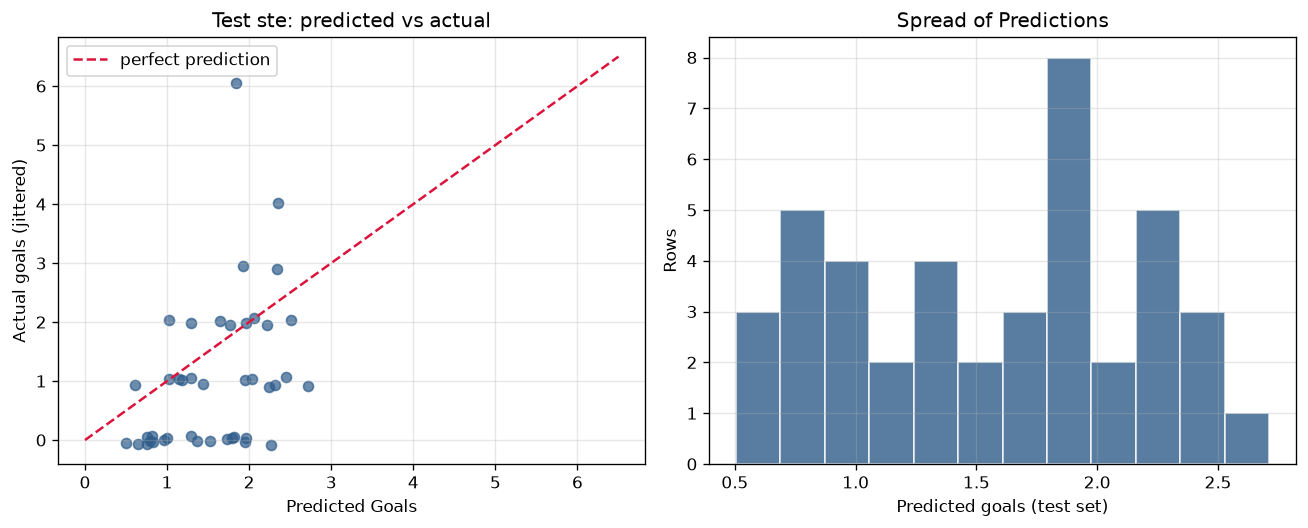

saved figure:p2_predicted_vs_actual_test.png

Share of OLS predictions below 0 goals (impossible vlaues):0.5%


In [64]:
section("C. PREDICTIVE PERFORMANCE")
Xtr, ytr = train[FEATURES], train[TARGET]
Xte, yte = test[FEATURES], test[TARGET]

lr=LinearRegression().fit(Xtr, ytr)
baseline=DummyRegressor(strategy="mean").fit(Xtr, ytr)

results=[]
for name, model in (("OLS(8 predictors)", lr),("Baseline (train mean)", baseline)):
    p_tr, p_te = model.predict(Xtr), model.predict(Xte)
    npred=len(FEATURES) if "OLS" in name else 0
    mt, ms = regression_metrics(ytr, p_tr, npred), regression_metrics(yte, p_te, npred)
    results.append({"model": name, "set":"train", **mt})
    results.append({"model": name, "set":"test", **ms})
hold=pd.DataFrame(results).round(3)
print("Hold-out evaluation (train=fit data, test= unseen matches):\n", hold.to_string(index=False))
hold.to_csv(TAB_DIR/ "p2_holdout_performance.csv", index=False)

# 5-FOLD Cv on All data, folds split by match so both rows of a match are always together
cv=GroupKFold(n_splits=CV_FOLDS)
scoring={"R2":"r2","RMSE":"neg_root_mean_squared_error","MAE":"neg_mean_absolute_error"}
cv_rows=[]
for name, model in (("OLS (8 predictors)", LinearRegression()), ("Baseline (mean)", DummyRegressor(strategy="mean"))):
    res=cross_validate(model, df[FEATURES], y_all, groups=df["match_id"], cv=cv, scoring=scoring)
    cv_rows.append({"model":name,
                    "R2_mean": res["test_R2"].mean(), "R2_sd":res['test_R2'].std(),
                   "RMSE_mean": -res["test_RMSE"].mean(), "RMSE_sd": res["test_RMSE"].std(),
                    "MAE_mean": -res["test_MAE"].mean(), "MAE_sd": res["test_MAE"].std()})
cv_table=pd.DataFrame(cv_rows).round(3)
print(f"\n{CV_FOLDS}-fold grouped cross-validation (all data):\n", cv_table.to_string(index=False))
cv_table.to_csv(TAB_DIR/ "p2_cross_validation.csv", index=False) 

#predicted vs actual on the test set
pred_te =lr.predict(Xte)
fig, axes = plt.subplots(1,2,figsize=(11,4.5))
ax=axes[0]
ax.scatter(pred_te, yte + rng.uniform(-0.1, 0.1, len(yte)), alpha=0.7, color="#2E5C8A")
lim= max(pred_te.max(), yte.max())+0.5
ax.plot([0, lim], [0, lim], color="crimson", ls="--", label="perfect prediction")
ax.set_xlabel("Predicted Goals")
ax.set_ylabel("Actual goals (jittered)")
ax.set_title("Test ste: predicted vs actual")
ax.legend()
ax=axes[1]
ax.hist(pred_te, bins=12, color="#2E5C8A", edgecolor="white", alpha=0.8)
ax.set_xlabel("Predicted goals (test set)")
ax.set_ylabel("Rows")
ax.set_title("Spread of Predictions")
save_fig("p2_predicted_vs_actual_test.png")

neg_share=(lr.predict(df[FEATURES])<0).mean()
print(f"\nShare of OLS predictions below 0 goals (impossible vlaues):{neg_share:.1%}")


### D. MODEL IMPROVEMENT: BACKWARD ELIMINATION (training data only -> no test lekage)

Removes the weakest predictors step by step(using training data only) and compares the reduced model with th full one.

Findings:

In [68]:
section(f"D. BACKWARD ELIMINATION (drop highest p-value while p > {ALPHA_ELM})on TRAINING data")
kept=list(FEATURES)
steps=[]
while True:
    m=sm.OLS(ytr, sm.add_constant(train[kept])).fit()
    pv=m.pvalues.drop("const")
    worst=pv.idxmax()
    if pv[worst] <= ALPHA_ELM or len(kept) == 1:
        break
    steps.append({"dropped":worst, "p_value":round(pv[worst],4),"adj_R2_before_drop":round(m.rsquared_adj,4)})
    kept.remove(worst)
print(pd.DataFrame(steps).to_string(index=False) if steps else "No variable dropped.")
print(f"\nVariables kept ({len(kept)}):{kept}")
pd.DataFrame(steps).to_csv(TAB_DIR/"p2_backward_elimination_stpes.csv", index=False) 

red_train=sm.OLS(ytr,sm.add_constant(train[kept])).fit()
red_all=sm.OLS(y_all, sm.add_constant(df[kept])).fit()
print("\n Redcued model (all 208 rows):\n", red_all.summary().tables[1])
(TAB_DIR/'p2_ols_redcued_summary.txt').write_text(str(red_all.summary()))

lr_red=LinearRegression().fit(train[kept],ytr)
cv_red=cross_validate(LinearRegression(),df[kept], y_all, groups=df["match_id"], cv=cv, scoring=scoring)
m_te_full= regression_metrics(yte, lr.predict(Xte), len(FEATURES))
m_te_red=regression_metrics(yte, lr_red.predict(test[kept]), len(kept))
full_cv=cv_table.iloc[0]

compare=pd.DataFrame([
    {"model": f"Full ({len(FEATURES)} predictors)", "Adj_R2_all_data": ols.rsquared_adj, "AIC": ols.aic, "BIC": ols.bic,
     "test_RMSE": m_te_full["RMSE"], "test_R2": m_te_full["R2"], "CV_RMSE": full_cv["RMSE_mean"], "CV_R2": full_cv["R2_mean"]},
    {"model": f"Reduced ({len(kept)} predictors)", "Adj_R2_all_data": red_all.rsquared_adj, "AIC": red_all.aic, "BIC": red_all.bic,
     "test_RMSE": m_te_red["RMSE"], "test_R2": m_te_red["R2"], "CV_RMSE": -cv_red["test_RMSE"].mean(), "CV_R2": cv_red["test_R2"].mean()},
]).round(3)
print("\nFull vs reduced model:\n", compare.to_string(index=False))
print("Caution: variables were chosen using the training matches only; the CV figure for the reduced model "
      "re-uses all data, so treat it as slightly optimistic.")
compare.to_csv(TAB_DIR / "p2_full_vs_reduced.csv", index=False)


D. BACKWARD ELIMINATION (drop highest p-value while p > 0.1)on TRAINING data

            dropped  p_value  adj_R2_before_drop
            is_host   0.8376              0.2651
        is_knockout   0.5904              0.2696
team_wc_appearances   0.4051              0.2728
         opp_ga_L10   0.2128              0.2742
        team_gf_L10   0.2075              0.2717
          rest_days   0.1383              0.2690

Variables kept (2):['team_fifa_points', 'opp_fifa_points']

 Redcued model (all 208 rows):
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const                0.8065      1.231      0.655      0.513      -1.620       3.233
team_fifa_points     0.0031      0.001      5.997      0.000       0.002       0.004
opp_fifa_points     -0.0027      0.001     -5.196      0.000      -0.004      -0.002

Full vs reduced model:
                  model  Adj_R2_all_d

### E. POISSON REGRESSION: COMPARISON (goals are non-negative counts)

Compare OLS with a Poisson regression, which respects that goals are counts. Used as a robustness/lmitations check.

Findings:

In [69]:
section("E. POISSON REGRESSION (comparison/limitation check)")
pois_all=sm.GLM(y_all, X_all, family=sm.families.Poisson()).fit()
print(pois_all.summary().tables[1])
disp=pois_all.pearson_chi2 / pois_all.df_resid
print(f"\nDispersion (Pearson chi2 / df)={disp:.2f} (about 1 means Poisson is reasonable; >1.5 means over-dispered)")
print(f"pseudo R2 (deviance-based)={1-pois_all.deviance / pois_all.null_deviance:.3f}")

pois_tr=sm.GLM(ytr, sm.add_constant(Xtr), family=sm.families.Poisson()).fit()
pred_pois=pois_tr.predict(sm.add_constant(Xte, has_constant="add"))
m_pois= regression_metrics(yte, pred_pois, len(FEATURES))
m_ols=regression_metrics(yte, pred_te, len(FEATURES))
cmp_pois=pd.DataFrame([
    {"model": "OLS", **{k_: m_ols[k_] for k_ in ("R2", "RMSE", "MAE")}, "min_prediction": pred_te.min()},
    {"model": "Poisson GLM", **{k_: m_pois[k_] for k_ in ("R2", "RMSE", "MAE")}, "min_prediction": float(pred_pois.min())},
]).round(3)
print("\nTest-set comparison:\n", cmp_pois.to_string(index=False))
cmp_pois.to_csv(TAB_DIR / "p2_ols_vs_poisson.csv", index=False)

sign_agree = (np.sign(ols.params[FEATURES]) == np.sign(pois_all.params[FEATURES])).mean()
print(f"Share of coefficients with the same sign in OLS and Poisson: {sign_agree:.0%}")



E. POISSON REGRESSION (comparison/limitation check)

                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                   0.0696      1.412      0.049      0.961      -2.698       2.837
team_fifa_points        0.0016      0.001      2.331      0.020       0.000       0.003
opp_fifa_points        -0.0014      0.000     -3.221      0.001      -0.002      -0.001
team_gf_L10             0.2149      0.115      1.875      0.061      -0.010       0.440
opp_ga_L10              0.2207      0.160      1.380      0.168      -0.093       0.534
is_host                 0.4617      0.211      2.187      0.029       0.048       0.875
is_knockout            -0.1193      0.147     -0.812      0.417      -0.407       0.169
rest_days              -0.1274      0.077     -1.653      0.098      -0.278       0.024
team_wc_appearances     0.0039      0.015      0.267      0.789   